# <font color='teal'> Deep networks with PyTorch </font>
### <font color='teal'> Deep Learning, part 2 of 3 </font>

    Notebook version: 1.0 (Oct 27, 2026)

    Authors: Jerónimo Arenas García (jarenas@ing.uc3m.es)
             Jesús Cid-Sueiro (jcid@tsc.uc3m.es)

    Changes: v.1.0. (Oct 27, 2026) - Second part of the original "Introduction to Neural
                                     Networks and Pytorch" notebook (v0.5, Oct 2025).
                                     Numerically stable softmax and per-sample losses, so
                                     that all the curves in the notebook are comparable.
                                     Normalization fit on the training partition only.
                                     Reproducible initialization. New Section 5 on
                                     generalization, with weight decay, dropout and
                                     early stopping.

In the previous notebook we implemented neural networks using numpy only. Everything was
explicit, including the gradients. Here we rewrite the same models with **PyTorch**, which
computes the gradients for us and runs on a GPU.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

size = 14
params = {'legend.fontsize': 'Large',
          'axes.labelsize': size,
          'axes.titlesize': size,
          'xtick.labelsize': size*0.75,
          'ytick.labelsize': size*0.75}
plt.rcParams.update(params)

## <font color='teal'> 1. Implementing Deep Networks with PyTorch </font>

* PyTorch is a Python library that provides different levels of abstraction for
  implementing deep neural networks

* The main features of PyTorch are:
    * Definition of numpy-like **n-dimensional tensors**. They can be stored in (or moved
      to) a GPU for **parallel execution** of operations
    * **Automatic calculation of gradients**, making *backward gradient calculation*
      transparent to the user
    * **Pre-defined components**: common loss functions, different types of NN layers,
      optimization methods, data loaders, etc, simplifying NN implementation and training
    * Provides **different levels of abstraction**, thus a good balance between
      flexibility and simplicity

* This notebook provides just a basic review of the main concepts necessary to train NNs
  with PyTorch, taking materials from:
    * <a href="https://pytorch.org/tutorials/beginner/pytorch_with_examples.html">Learning PyTorch with Examples</a>, by Justin Johnson
    * <a href="https://pytorch.org/tutorials/beginner/nn_tutorial.html">What is *torch.nn* really?</a>, by Jeremy Howard
    * <a href="https://www.kaggle.com/kanncaa1/pytorch-tutorial-for-deep-learning-lovers">Pytorch Tutorial for Deep Learning Lovers</a>, by Kaggle user kanncaa1

### <font color='teal'> 1.1. Installation and PyTorch introduction</font>

* PyTorch can be installed with or without GPU support
    * If you have an Anaconda installation, you can install it from the command line,
      using the <a href="https://pytorch.org/">instructions of the project website</a>

* PyTorch is also preinstalled in Google Colab with free GPU access
    * Follow Runtime -> Change runtime type, and select a GPU for HW acceleration

* Please, refer to the PyTorch [getting started](https://pytorch.org/get-started/locally/)
  tutorial for a quick introduction regarding tensor definition, GPU vs CPU storage of
  tensors, operations, and the bridge to numpy

### <font color='teal'> 1.2. Torch tensors (very) general overview</font>

We can create tensors with different construction methods provided by the library, either
to create new tensors from scratch or from a numpy array

In [ ]:
import torch

# Fix the seeds, so that the results are reproducible from run to run
torch.manual_seed(42)
rng = np.random.default_rng(42)

digitsX = np.load('./data/Sign-language-digits-dataset/X.npy')
digitsY = np.load('./data/Sign-language-digits-dataset/Y.npy')
digitsX_flatten = digitsX.reshape(digitsX.shape[0], -1)

x = torch.rand((100, 200))
digitsX_flatten_tensor = torch.from_numpy(digitsX_flatten)

print(x.dtype)
print(digitsX_flatten_tensor.size())

* Tensors can be converted back to numpy arrays
* Note that in this case, a tensor and its corresponding numpy array **will share memory**

Operations and slicing use a syntax similar to numpy

In [ ]:
print('Size of tensor x:', x.size())
print('Tranpose of vector has size', x.t().size()) #Transpose and compute size
print('Extracting upper left matrix of size 3 x 3:', x[:3,:3])
print(x.mm(x.t()).size())  #mm for matrix multiplications
xpx = x.add(x)
xpx2 = torch.add(x,x)
print((xpx != xpx2).sum())   # Since all are equal, count of different terms is zero

* Adding underscore performs operations "*in place*", e.g., ```x.add_(y)```

If a GPU is available, tensors can be moved to and from the GPU device Operations on tensors stored in a GPU will be carried out using GPU resources and will typically be highly parallelized

In [ ]:
#Select device depending on GPU

def get_best_device():
    if torch.cuda.is_available():  # NVIDIA GPU
        return torch.device("cuda")
    elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():  # Apple Silicon GPU
        return torch.device("mps")
    elif hasattr(torch.version, "hip") and torch.version.hip is not None:  # AMD ROCm GPU
        return torch.device("cuda")  # ROCm uses CUDA device type internally
    else:
        print("No supported GPU backend found → using CPU.")
        return torch.device("cpu")


device = get_best_device()

x = torch.randn(3, 3).to(device)
y = x + x

### <font color='teal'> 1.3. Automatic gradient calculation </font>

PyTorch tensors have a property ```requires_grad```. When true, PyTorch automatic gradient
calculation will be activated for that variable

* In order to compute these derivatives numerically, PyTorch keeps track of all operations
  carried out on these variables, organizing them in a forward computation graph.
* When executing the ```backward()``` method, derivatives will be calculated
* However, this should only be activated when necessary, to save computation

This is the piece that replaces the whole `backward()` function that we had to derive by
hand in the previous notebook.

In [ ]:
x = torch.rand((5, 5)) + 0.5     # values away from zero, so that log(x) is well defined
x.requires_grad = True

y = (3 * torch.log(x)).sum()
y.backward()

print('Gradient computed by PyTorch:')
print(x.grad[:2, :2])
print('Analytical gradient, 3/x:')
print(3 / x[:2, :2].detach())

x.requires_grad = False
x.grad.zero_()
print('Automatic gradient calculation is deactivated, and gradients set to zero')

#### <font color='olive'>Exercise 1</font>

**1.1.** Initialize a tensor `x` with the upper left $5 \times 10$ submatrix of the
flattened digits. Activate `x` as a variable required for gradient computation.

In [ ]:
# Write your solution here


print(x)

**1.2.** Compute output vector `y` as the component-wise square root of `x`

In [ ]:
# y = <FILL IN>

print(y)

**1.3.** Compute scalar value ```z``` as the sum of all elements in `y` squared. You can easily test if it is equal to the sum of all elements in `x`.

In [ ]:
# z = <FILL IN>

print(z)

**1.4.** Compute the derivatives of `z` with the `backward` method, an check if they are correct.

**Note:** The backward method can only be run on scalar variables

In [ ]:
# Write your solution here

**1.5.** If you try to run the last cell multiple times, you will likely get an error.
Implement the necessary modifications so that you can run the backward method multiple
times, but the gradient does not change from run to run

In [ ]:
# Write your solution here

## <font color='teal'> 2. Feed Forward Neural Networks using PyTorch </font>

In this section we will change our code for neural network evaluation and training to use
tensors instead of numpy arrays. We will work with the `sign digits` dataset.

We will introduce all concepts using a single layer perceptron (softmax regression), and
then implement networks with additional hidden layers

### <font color='olive'> 2.1. Using automatic differentiation </font>

We start by loading the data, and converting it to tensors.

* As a first step, we refactor our code to use tensor operations
* We do not need to pay too much attention to particular details regarding tensor
  operations, since these will not be necessary when moving to higher PyTorch abstraction
  levels
* We do not need to implement gradient calculation. PyTorch will take care of that

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# Generate train and validation data, shuffle
X_train, X_val, y_train, y_val = train_test_split(
    digitsX_flatten, digitsY, test_size=0.2, random_state=42, shuffle=True)

# Normalization: the scaler is fit on the training partition only
min_max_scaler = MinMaxScaler(feature_range=(-.5, .5))
X_train = min_max_scaler.fit_transform(X_train)
X_val = min_max_scaler.transform(X_val)

# Convert to torch tensors. We use float32, the default type of the torch layers:
# mixing float32 and float64 tensors is a frequent source of errors
X_train_torch = torch.tensor(X_train, dtype=torch.float32)
X_val_torch = torch.tensor(X_val, dtype=torch.float32)
y_train_torch = torch.tensor(y_train, dtype=torch.float32)
y_val_torch = torch.tensor(y_val, dtype=torch.float32)

print('Training data:', X_train_torch.shape, X_train_torch.dtype)
print('Validation data:', X_val_torch.shape)

In [ ]:
# Define some useful functions
def softmax(t):
    """Compute softmax values for each set of scores in t.

    As in the numpy version, the maximum of each row is subtracted before taking the
    exponential, to avoid overflow. (torch.softmax does exactly this, and in practice you
    would simply call it.)
    """
    e_t = (t - t.max(dim=-1, keepdim=True).values).exp()
    return e_t / e_t.sum(dim=-1, keepdim=True)

def model(w, b, x):
    # Compute the probabilistic prediction
    return softmax(x.mm(w) + b)

def accuracy(y, q):
    return (y.argmax(axis=-1) == q.argmax(axis=-1)).float().mean()

def nll(y, q, eps=1e-12):
    # Average cross entropy per sample: sum over classes, mean over samples.
    return -(y * q.clamp_min(eps).log()).sum(dim=-1).mean()

Note that:

* The syntax is a bit different because the input variables are tensors, not arrays
* This time we did not need to implement the backward function

In [ ]:
# Parameter initialization
W = .1 * torch.randn(X_train_torch.size()[1], y_train_torch.size()[1])
W.requires_grad_()
b = torch.zeros(y_train_torch.size()[1], requires_grad=True)

epochs = 500
rho = .5

loss_train = np.zeros(epochs)
loss_val = np.zeros(epochs)
acc_train = np.zeros(epochs)
acc_val = np.zeros(epochs)

In [ ]:
# Network training
for epoch in range(epochs):

    print(f'Current epoch: {epoch + 1}  \r', end="")

    # Compute network output and cross-entropy loss
    pred = model(W, b, X_train_torch)
    loss = nll(y_train_torch, pred)

    # Compute gradients
    loss.backward()

    # Deactivate gradient automatic updates
    with torch.no_grad():
        #Computing network performance after iteration
        loss_train[epoch] = loss.item()
        acc_train[epoch] = accuracy(y_train_torch, pred).item()
        pred_val = model(W, b, X_val_torch)
        loss_val[epoch] = nll(y_val_torch, pred_val).item()
        acc_val[epoch] = accuracy(y_val_torch, pred_val).item()

        #Weight update
        W -= rho * W.grad
        b -= rho * b.grad

        # Reset gradients
        W.grad.zero_()
        b.grad.zero_()

**It is important to deactivate gradient updates after the network has been evaluated on training data, and gradients of the loss function have been computed:**
   - Validation data should never be used for updating the network parameters
   - Save computation to accelerate the code

In [ ]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1), plt.plot(loss_train, 'b'), plt.plot(loss_val, 'r')
plt.legend(['train', 'val']), plt.title('Cross-entropy loss'), plt.xlabel('epoch')
plt.subplot(1, 2, 2), plt.plot(acc_train, 'b'), plt.plot(acc_val, 'r')
plt.legend(['train', 'val']), plt.title('Accuracy'), plt.xlabel('epoch')
plt.show()
print('Final validation accuracy:', acc_val[-1])

### <font color='olive'> 2.2. Using the torch *nn* module </font>

The PyTorch *nn* module provides many attributes and methods that make the implementation
and training of neural networks simpler

* ```nn.Module``` and ```nn.Parameter``` allow us to implement a more concise training loop

* ```nn.Module``` is a PyTorch class that will be used to encapsulate and design a specific
  neural network, thus, it is central to the implementation of deep neural nets using
  PyTorch

* ```nn.Parameter``` allows the definition of trainable network parameters. In this way,
  we simplify the implementation of the training loop.

* All parameters defined with ```nn.Parameter``` will have ```requires_grad = True```

In [ ]:
from torch import nn

class my_multiclass_net(nn.Module):
    def __init__(self, nin, nout):
        """ This method initializes the network parameters.
        Parameters nin and nout stand for the number of input parameters (features in X)
        and output parameters (number of classes) """
        super().__init__()
        self.W = nn.Parameter(.1 * torch.randn(nin, nout))
        self.b = nn.Parameter(torch.zeros(nout))

    def forward(self, x):
        return softmax(x.mm(self.W) + self.b)

In [ ]:
my_net = my_multiclass_net(X_train_torch.size()[1], y_train_torch.size()[1])

epochs = 500
rho = .5

loss_train = np.zeros(epochs)
loss_val = np.zeros(epochs)
acc_train = np.zeros(epochs)
acc_val = np.zeros(epochs)

for epoch in range(epochs):

    print(f'Current epoch: {epoch + 1}  \r', end="")

    #Compute network output and cross-entropy loss
    pred = my_net(X_train_torch)
    loss = nll(y_train_torch, pred)

    #Compute gradients
    loss.backward()

    #Deactivate gradient automatic updates
    with torch.no_grad():
        #Computing network performance after iteration
        loss_train[epoch] = loss.item()
        acc_train[epoch] = accuracy(y_train_torch, pred).item()
        pred_val = my_net(X_val_torch)
        loss_val[epoch] = nll(y_val_torch, pred_val).item()
        acc_val[epoch] = accuracy(y_val_torch, pred_val).item()

        #Weight update
        for p in my_net.parameters():
            p -= p.grad * rho
        #Reset gradients
        my_net.zero_grad()

In [ ]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1), plt.plot(loss_train, 'b'), plt.plot(loss_val, 'r')
plt.legend(['train', 'val']), plt.title('Cross-entropy loss'), plt.xlabel('epoch')
plt.subplot(1, 2, 2), plt.plot(acc_train, 'b'), plt.plot(acc_val, 'r')
plt.legend(['train', 'val']), plt.title('Accuracy'), plt.xlabel('epoch')
plt.show()
print('Final validation accuracy:', acc_val[-1])

* ```nn.Module``` comes with several kinds of pre-defined layers, thus making it even simpler to implement neural networks

* We can also import the Cross Entropy Loss from ```nn.Module```. When doing so:
    - We do not have to compute the softmax, since the ```nn.CrossEntropyLoss``` already does so
    - ```nn.CrossEntropyLoss``` receives two input arguments, the first is the output of the network, and the second is the true label as a 1-D tensor (i.e., an array of integers, one-hot encoding should not be used)

In [ ]:
from torch import nn

class my_multiclass_net(nn.Module):
    def __init__(self, nin, nout):
        """Note that now, we do not even need to initialize network parameters ourselves"""
        super().__init__()
        self.lin = nn.Linear(nin, nout)

    def forward(self, x):
        return self.lin(x)

loss_func = nn.CrossEntropyLoss()

In [ ]:
my_net = my_multiclass_net(X_train_torch.size()[1], y_train_torch.size()[1])

epochs = 500
rho = .1

loss_train = np.zeros(epochs)
loss_val = np.zeros(epochs)
acc_train = np.zeros(epochs)
acc_val = np.zeros(epochs)

for epoch in range(epochs):

    print(f'Current epoch: {epoch + 1}  \r', end="")

    #Compute network output and cross-entropy loss
    pred = my_net(X_train_torch)
    loss = loss_func(pred, y_train_torch.argmax(axis=-1))

    #Compute gradients
    loss.backward()

    #Deactivate gradient automatic updates
    with torch.no_grad():
        #Computing network performance after iteration
        loss_train[epoch] = loss.item()
        acc_train[epoch] = accuracy(y_train_torch, pred).item()
        pred_val = my_net(X_val_torch)
        loss_val[epoch] = loss_func(pred_val, y_val_torch.argmax(axis=-1)).item()
        acc_val[epoch] = accuracy(y_val_torch, pred_val).item()

        #Weight update
        for p in my_net.parameters():
            p -= p.grad * rho
        #Reset gradients
        my_net.zero_grad()

In [ ]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1), plt.plot(loss_train, 'b'), plt.plot(loss_val, 'r')
plt.legend(['train', 'val']), plt.title('Cross-entropy loss'), plt.xlabel('epoch')
plt.subplot(1, 2, 2), plt.plot(acc_train, 'b'), plt.plot(acc_val, 'r')
plt.legend(['train', 'val']), plt.title('Accuracy'), plt.xlabel('epoch')
plt.show()
print('Final validation accuracy:', acc_val[-1])

Note that a faster convergence is observed in this case. It is actually due to the
initialization used by `nn.Linear`, which scales the initial weights with the number of
inputs of the layer, instead of using a fixed standard deviation of 0.1.

#### <font color='olive'> 2.3. Network Optimization </font>

We cover in this subsection two different aspects about network training using PyTorch:

  * Using ```torch.optim``` allows an easier and more interpretable encoding of neural network training, and opens the door to more sophisticated training algorithms
  * Using minibatches can speed up network convergence

`torch.optim` provides two convenient methods for neural network training:

  * `opt.step()` updates all network parameters using current gradients
  * `opt.zero_grad()` resets all network parameters

In [ ]:
from torch import optim

my_net = my_multiclass_net(X_train_torch.size()[1], y_train_torch.size()[1])
opt = optim.SGD(my_net.parameters(), lr=0.1)

epochs = 500

loss_train = np.zeros(epochs)
loss_val = np.zeros(epochs)
acc_train = np.zeros(epochs)
acc_val = np.zeros(epochs)

for epoch in range(epochs):

    print(f'Current epoch: {epoch + 1}  \r', end="")

    # Compute network output and cross-entropy loss
    pred = my_net(X_train_torch)
    loss = loss_func(pred, y_train_torch.argmax(axis=-1))

    # Compute gradients
    loss.backward()

    # Deactivate gradient automatic updates
    with torch.no_grad():
        #Computing network performance after iteration
        loss_train[epoch] = loss.item()
        acc_train[epoch] = accuracy(y_train_torch, pred).item()
        pred_val = my_net(X_val_torch)
        loss_val[epoch] = loss_func(pred_val, y_val_torch.argmax(axis=-1)).item()
        acc_val[epoch] = accuracy(y_val_torch, pred_val).item()

    opt.step()
    opt.zero_grad()

Note network optimization is carried out outside ```torch.no_grad()``` but network evaluation (other than forward output calculation for the training patterns) still needs to deactivate gradient updates

In [ ]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1), plt.plot(loss_train, 'b'), plt.plot(loss_val, 'r')
plt.legend(['train', 'val']), plt.title('Cross-entropy loss'), plt.xlabel('epoch')
plt.subplot(1, 2, 2), plt.plot(acc_train, 'b'), plt.plot(acc_val, 'r')
plt.legend(['train', 'val']), plt.title('Accuracy'), plt.xlabel('epoch')
plt.show()
print('Final validation accuracy:', acc_val[-1])

##### <font color='olive'> Exercise 2 </font>

Implement network training with two modifications:

  * Replace the SGD optimization method by the Adam algorithm. You can refer to the
    <a href="https://pytorch.org/docs/stable/optim.html">official documentation</a> and get
    help on this and other methods.
  * Implement an adaptive learning rate using `torch.optim.lr_scheduler` (for instance, you
    can try the <a href="https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ExponentialLR.html#torch.optim.lr_scheduler.ExponentialLR">ExponentialLR</a> scheduler).

In [ ]:
# Write your solution here

### <font color='olive'> 2.4. The DataLoader method. Using SGD with minibatches </font>

Each epoch of the previous implementation of network training was actually implementing
Gradient Descent
* In Stochastic Gradient Descent (SGD) only a small subset of training patterns (a
  *minibatch*) is used at every iteration
* In each epoch we iterate over all training patterns, sequentially selecting
  non-overlapping *minibatches*
* Overall, convergence is usually faster than when using standard Gradient Descent
* Torch provides methods that simplify the implementation of this strategy

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

train_ds = TensorDataset(X_train_torch, y_train_torch)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True)

In [ ]:
from torch import optim

my_net = my_multiclass_net(X_train_torch.size()[1], y_train_torch.size()[1])
opt = optim.SGD(my_net.parameters(), lr=0.1)

epochs = 200

loss_train = np.zeros(epochs)
loss_val = np.zeros(epochs)
acc_train = np.zeros(epochs)
acc_val = np.zeros(epochs)

for epoch in range(epochs):

    print(f'Current epoch: {epoch + 1}  \r', end="")

    for xb, yb in train_dl:

        #Compute network output and cross-entropy loss for current minibatch
        pred = my_net(xb)
        loss = loss_func(pred, yb.argmax(axis=-1))

        #Compute gradients and optimize parameters
        loss.backward()
        opt.step()
        opt.zero_grad()

    #At the end of each epoch, evaluate overall network performance
    with torch.no_grad():
        #Computing network performance after iteration
        pred = my_net(X_train_torch)
        loss_train[epoch] = loss_func(pred, y_train_torch.argmax(axis=-1)).item()
        acc_train[epoch] = accuracy(y_train_torch, pred).item()
        pred_val = my_net(X_val_torch)
        loss_val[epoch] = loss_func(pred_val, y_val_torch.argmax(axis=-1)).item()
        acc_val[epoch] = accuracy(y_val_torch, pred_val).item()

In [ ]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1), plt.plot(loss_train, 'b'), plt.plot(loss_val, 'r')
plt.legend(['train', 'val']), plt.title('Cross-entropy loss'), plt.xlabel('epoch')
plt.subplot(1, 2, 2), plt.plot(acc_train, 'b'), plt.plot(acc_val, 'r')
plt.legend(['train', 'val']), plt.title('Accuracy'), plt.xlabel('epoch')
plt.show()
print('Final validation accuracy:', acc_val[-1])

### <font color='olive'> 2.5. Multi-layer networks using ```nn.Sequential``` </font>

PyTorch simplifies considerably the implementation of neural network training, since we do
not need to implement derivatives ourselves

We can also make a simpler implementation of multilayer networks using the
```nn.Sequential``` function

It returns directly a network with the requested topology, including parameters **and the
forward evaluation method**

Since we are going to train several networks from now on, we also encapsulate the training
loop in a function. It is exactly the same loop as above.

In [ ]:
def train_net(net, train_dl, X_train, y_train, X_val, y_val, epochs=200,
              lr=0.01, weight_decay=0.0, optimizer='SGD', verbose=True):
    """Trains a network and returns the loss and accuracy curves.

    weight_decay implements L2 regularization (see Section 3).
    """
    loss_func = nn.CrossEntropyLoss()
    if optimizer == 'SGD':
        opt = optim.SGD(net.parameters(), lr=lr, weight_decay=weight_decay)
    else:
        opt = optim.Adam(net.parameters(), lr=lr, weight_decay=weight_decay)

    curves = {k: np.zeros(epochs) for k in ('loss_train', 'loss_val', 'acc_train', 'acc_val')}

    for epoch in range(epochs):
        if verbose:
            print(f'Current epoch: {epoch + 1}  \r', end="")

        # --- training: the network must be in train mode (relevant for dropout)
        net.train()
        for xb, yb in train_dl:
            pred = net(xb)
            loss = loss_func(pred, yb.argmax(axis=-1))
            loss.backward()
            opt.step()
            opt.zero_grad()

        # --- evaluation: eval mode, and no gradients
        net.eval()
        with torch.no_grad():
            pred = net(X_train)
            curves['loss_train'][epoch] = loss_func(pred, y_train.argmax(axis=-1)).item()
            curves['acc_train'][epoch] = accuracy(y_train, pred).item()
            pred_val = net(X_val)
            curves['loss_val'][epoch] = loss_func(pred_val, y_val.argmax(axis=-1)).item()
            curves['acc_val'][epoch] = accuracy(y_val, pred_val).item()

    return curves

In [ ]:
torch.manual_seed(42)

n_in = X_train_torch.size()[1]
n_out = y_train_torch.size()[1]

my_net = nn.Sequential(
    nn.Linear(n_in, 200),
    nn.ReLU(),
    nn.Linear(200, 50),
    nn.ReLU(),
    nn.Linear(50, 20),
    nn.ReLU(),
    nn.Linear(20, n_out)
)

curves = train_net(my_net, train_dl, X_train_torch, y_train_torch,
                   X_val_torch, y_val_torch, epochs=300, lr=0.01)

loss_train, loss_val = curves['loss_train'], curves['loss_val']
acc_train, acc_val = curves['acc_train'], curves['acc_val']

In [ ]:
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1), plt.plot(loss_train, 'b'), plt.plot(loss_val, 'r')
plt.legend(['train', 'val']), plt.title('Cross-entropy loss'), plt.xlabel('epoch')
plt.subplot(1, 2, 2), plt.plot(acc_train, 'b'), plt.plot(acc_val, 'r')
plt.legend(['train', 'val']), plt.title('Accuracy'), plt.xlabel('epoch')
plt.show()
print('Final validation accuracy:', acc_val[-1])

## <font color='teal'> 3. Generalization</font>

As the number of neurons and parameters in a neural network model grows, the training
process can incur in **over-fitting** issues: the model learns to perform exceptionally
well on the training data but fails to **generalize** effectively to new, unseen data: the
model captures noise and specific details in the training data, rather than the underlying
patterns. Overfit models have poor predictive performance on data they haven't seen before
because they essentially memorize the training data rather than learning the true
relationships.

Look at the curves of the previous network: the training accuracy reaches 100 % while the
validation accuracy saturates well below it, and the validation loss starts to **increase**
while the training loss keeps going down. That gap is over-fitting.

A standard procedure to avoid overfitting is cross validation. We can train neural network
configurations with different complexity, and select the most appropriate using a
validation set, or through $n$-fold cross validation. However, the number of possible
configurations (number of layers, neurons per layer, etc) may be too large, and combining
cross-validation with other techniques is usually more efficient. These are some of them.

### <font color='teal'> 3.1. Regularization by a penalty term</font>

The loss function is extended with an additional term penalizing large weights. Two common
examples of regularization for an empirical risk $R({\bf w})$ are:

  - L2 regularization:  $R({\bf w}) + \lambda \|{\bf w}\|^2$
  - L1 regularization:  $R({\bf w}) + \lambda \|{\bf w}\|_1$

In PyTorch, L2 regularization does not need to be written into the loss: every optimizer
accepts a `weight_decay` argument that adds $\lambda \|{\bf w}\|^2$ to the objective,
which amounts to shrinking the weights by a factor $(1 - 2\lambda\rho)$ at each update.

In [ ]:
torch.manual_seed(42)

net_l2 = nn.Sequential(
    nn.Linear(n_in, 200), nn.ReLU(),
    nn.Linear(200, 50), nn.ReLU(),
    nn.Linear(50, 20), nn.ReLU(),
    nn.Linear(20, n_out)
)

curves_l2 = train_net(net_l2, train_dl, X_train_torch, y_train_torch,
                      X_val_torch, y_val_torch, epochs=300, lr=0.01, weight_decay=1e-2)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(curves['loss_val'], 'r'), plt.plot(curves_l2['loss_val'], 'g')
plt.legend(['no regularization', 'weight decay 1e-2']), plt.title('Validation loss')
plt.xlabel('epoch')
plt.subplot(1, 2, 2)
plt.plot(curves['acc_val'], 'r'), plt.plot(curves_l2['acc_val'], 'g')
plt.legend(['no regularization', 'weight decay 1e-2']), plt.title('Validation accuracy')
plt.xlabel('epoch')
plt.show()

print(f"                                     no reg.   weight decay")
print(f"Best validation accuracy:            {curves['acc_val'].max():.4f}    {curves_l2['acc_val'].max():.4f}")
print(f"Validation loss at the last epoch:   {curves['loss_val'][-1]:.4f}    {curves_l2['loss_val'][-1]:.4f}")

Look carefully at what changed and what did not. The **accuracy** is almost the same, but
the **validation loss** no longer grows without bound. The unregularized network does not
make many more mistakes than the regularized one: it makes them with much more confidence,
and the cross entropy punishes exactly that. This is a good reminder that *the metric you
look at decides what you conclude*.

#### <font color='olive'>Exercise 3</font>

Explore the effect of the `weight_decay` parameter: try values between $10^{-5}$ and
$10^{-1}$ and plot the best validation accuracy as a function of $\lambda$. Does the
training accuracy behave in the same way?

In [ ]:
# Write your solution here

### <font color='teal'> 3.2. Dropout</font>

During training, dropout randomly "drops out" (deactivates) a fraction $p$ of the neurons
of a layer, preventing the co-adaptation of neurons and reducing overfitting. It helps the
model generalize better by making it more robust and less reliant on specific neurons
during prediction. **During inference, dropout is turned off** and all neurons are used.

<center><a href="https://medium.com/analytics-vidhya/a-simple-introduction-to-dropout-regularization-with-code-5279489dda1e">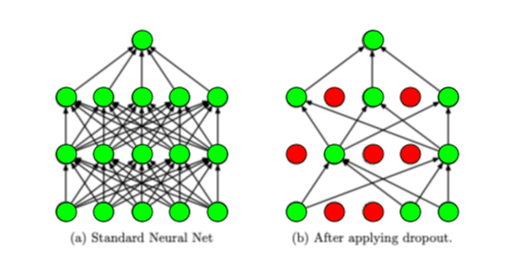Image Source</a></center>

In PyTorch, dropout is simply another layer, `nn.Dropout(p)`, that is inserted after the
activation of the layers we want to regularize. This is the reason why the training loop
has to call `net.train()` and `net.eval()`: the dropout layer behaves differently in each
mode, and **forgetting `net.eval()` before evaluating is one of the most common bugs in
PyTorch code**.

In [ ]:
torch.manual_seed(42)

net_drop = nn.Sequential(
    nn.Linear(n_in, 200), nn.ReLU(), nn.Dropout(0.5),
    nn.Linear(200, 50), nn.ReLU(), nn.Dropout(0.5),
    nn.Linear(50, 20), nn.ReLU(),
    nn.Linear(20, n_out)
)

curves_drop = train_net(net_drop, train_dl, X_train_torch, y_train_torch,
                        X_val_torch, y_val_torch, epochs=300, lr=0.01)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(curves['acc_train'], 'b'), plt.plot(curves_drop['acc_train'], 'c')
plt.legend(['no dropout', 'dropout 0.5']), plt.title('Training accuracy'), plt.xlabel('epoch')
plt.subplot(1, 2, 2)
plt.plot(curves['acc_val'], 'r'), plt.plot(curves_drop['acc_val'], 'm')
plt.legend(['no dropout', 'dropout 0.5']), plt.title('Validation accuracy'), plt.xlabel('epoch')
plt.show()

print(f"Best validation accuracy without dropout: {curves['acc_val'].max():.4f}")
print(f"Best validation accuracy with dropout:    {curves_drop['acc_val'].max():.4f}")

#### <font color='olive'>Exercise 4</font>

Try other values of $p$ (0.1, 0.2, 0.5, 0.8) and also apply dropout to a different set of
layers. Note the characteristic signature of dropout in the curves: the **training**
accuracy gets worse, and that is not a failure.

In [ ]:
# Write your solution here

### <font color='teal'> 3.3. Early stopping</font>

Early stopping monitors the model's performance on a validation set during training. If
the validation performance starts to degrade (e.g. the validation loss increases), training
is stopped, and the model with the best performance on the validation data is kept.

Two details make the difference between a correct implementation and a useless one:

* what is kept is **the best model, not the last one**. We save a copy of the parameters
  (`state_dict`) whenever the validation loss improves;
* training is not stopped the first time the validation loss goes up (it fluctuates). We
  wait for a number of epochs without improvement, called the **patience**.

In [ ]:
import copy

def train_with_early_stopping(net, train_dl, X_train, y_train, X_val, y_val,
                              epochs=300, lr=0.01, patience=20, monitor='loss'):
    loss_func = nn.CrossEntropyLoss()
    opt = optim.SGD(net.parameters(), lr=lr)

    curves = {k: [] for k in ('loss_train', 'loss_val', 'acc_train', 'acc_val')}
    best_loss, best_epoch, best_state = np.inf, 0, None

    for epoch in range(epochs):
        net.train()
        for xb, yb in train_dl:
            loss = loss_func(net(xb), yb.argmax(axis=-1))
            loss.backward()
            opt.step()
            opt.zero_grad()

        net.eval()
        with torch.no_grad():
            pred = net(X_train)
            curves['loss_train'].append(loss_func(pred, y_train.argmax(axis=-1)).item())
            curves['acc_train'].append(accuracy(y_train, pred).item())
            pred_val = net(X_val)
            val_loss = loss_func(pred_val, y_val.argmax(axis=-1)).item()
            curves['loss_val'].append(val_loss)
            curves['acc_val'].append(accuracy(y_val, pred_val).item())

        # The quantity we monitor decides which model we keep
        score = val_loss if monitor == 'loss' else -curves['acc_val'][-1]

        if score < best_loss:
            best_loss, best_epoch = score, epoch
            best_state = copy.deepcopy(net.state_dict())
        elif epoch - best_epoch >= patience:
            print(f'\nEarly stopping at epoch {epoch + 1}. '
                  f'Best epoch was {best_epoch + 1}.')
            break

    net.load_state_dict(best_state)      # restore the best model, not the last one
    return {k: np.array(v) for k, v in curves.items()}, best_epoch


torch.manual_seed(42)
net_es = nn.Sequential(
    nn.Linear(n_in, 200), nn.ReLU(),
    nn.Linear(200, 50), nn.ReLU(),
    nn.Linear(50, 20), nn.ReLU(),
    nn.Linear(20, n_out)
)

curves_es, best_epoch = train_with_early_stopping(
    net_es, train_dl, X_train_torch, y_train_torch, X_val_torch, y_val_torch,
    epochs=300, lr=0.01, patience=20)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(curves_es['loss_train'], 'b'), plt.plot(curves_es['loss_val'], 'r')
plt.axvline(best_epoch, color='k', ls='--')
plt.legend(['train', 'val', 'selected model']), plt.title('Cross-entropy loss')
plt.xlabel('epoch')
plt.subplot(1, 2, 2)
plt.plot(curves_es['acc_train'], 'b'), plt.plot(curves_es['acc_val'], 'r')
plt.axvline(best_epoch, color='k', ls='--')
plt.legend(['train', 'val', 'selected model']), plt.title('Accuracy'), plt.xlabel('epoch')
plt.show()

print(f'Model selected at epoch {best_epoch + 1}')
print(f'  validation accuracy of the selected model: {curves_es["acc_val"][best_epoch]:.4f}')
print(f'  best validation accuracy seen during training: {curves_es["acc_val"].max():.4f} '
      f'(epoch {curves_es["acc_val"].argmax() + 1})')

Note the two numbers printed above: the model selected by early stopping on the validation
**loss** is not the one with the best validation **accuracy**. The loss reaches its minimum
fairly early and then grows, because the network becomes overconfident, while the accuracy
keeps improving for a while. Neither criterion is wrong, but they select different models:
decide in advance which one matters for your problem, and monitor that one. Try
`monitor='accuracy'` above and compare.

### <font color='teal'> 3.4. Data augmentation</font>

Data augmentation applies random transformations to the training data to create additional
training examples: rotations, scalings, crops, flips, brightness adjustments, and so on. By
exposing the network to a wider variety of training examples, the model learns to be
invariant to these transformations and generalizes better to unseen data.

It is particularly natural for images, where the transformations that leave the label
unchanged are obvious, so we will come back to it in the next notebook, where
`torchvision` provides them ready to use.

#### <font color='olive'>Exercise 5</font>

Combine the three techniques (weight decay, dropout and early stopping) in a single network
and compare with the unregularized baseline. Which of them gives the largest improvement on
this dataset? Is the combination better than the best of them alone?

In [ ]:
# Write your solution here

## <font color='teal'> 4. Wrap-up </font>

With PyTorch we have rewritten the same models of the previous notebook without deriving a
single gradient, and we have added the tools that make training work in practice:
minibatches, optimizers, and three ways of controlling over-fitting.

Everything so far treats an image as a flat vector of 4096 pixels, which throws away the
fact that neighboring pixels are related. In the next session we will use **convolutional
networks**, a topology designed for exactly that.